# 41. Probability and Statistics through Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Conditioning a bivariate Gaussian. Left: samples from $N(0,\Sigma)$ with correlation $0.8$, the $1$-, $2$- and $3$-standard-deviation ellipses, and the regression line $\mathbb E[x_1\mid x_2]=\Sigma_{12}\Sigma_{22}^{-1}x_2$ (red). Right: the conditional density of $x_1$ given $x_2=1.5$ (red), centred on the regression line with variance equal to the Schur complement $\Sigma_{11}-\Sigma_{12}^2/\Sigma_{22}$, narrower than the marginal density of $x_1$ (grey).

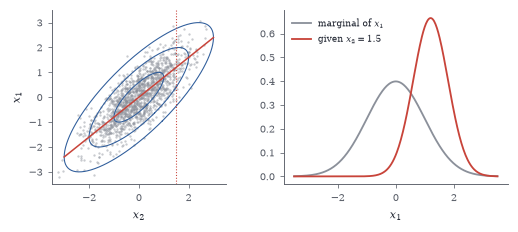

In [2]:
rng = np.random.default_rng(0); Sg = np.array([[1.0, 0.8], [0.8, 1.0]]); Cg = np.linalg.cholesky(Sg); Z = (Cg @ rng.normal(size=(2, 1500))).T
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
axs[0].plot(Z[:, 1], Z[:, 0], ".", color=GRAY, ms=1, alpha=0.5); lam, U = np.linalg.eigh(Sg); th = np.linspace(0, 2 * np.pi, 200)
for r in (1, 2, 3):
    E = U @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(th), np.sin(th)])) * r; axs[0].plot(E[1], E[0], color=BLUE, lw=0.7)
xx = np.linspace(-3, 3, 10); axs[0].plot(xx, 0.8 * xx, color=RED, lw=1); axs[0].axvline(1.5, color=RED, ls=":", lw=0.7)
axs[0].set_xlabel("$x_2$"); axs[0].set_ylabel("$x_1$"); axs[0].set_aspect("equal"); axs[0].set_xlim(-3.5, 3.5); axs[0].set_ylim(-3.5, 3.5)
g = np.linspace(-3.5, 3.5, 300); sc = 1 - 0.64
axs[1].plot(g, np.exp(-g**2 / 2) / np.sqrt(2 * np.pi), color=GRAY, label="marginal of $x_1$"); axs[1].plot(g, np.exp(-(g - 1.2) ** 2 / (2 * sc)) / np.sqrt(2 * np.pi * sc), color=RED, label="given $x_2=1.5$")
axs[1].set_xlabel("$x_1$"); axs[1].legend(fontsize=6)

A Kalman filter tracking an object moving with nearly constant velocity in the plane, from noisy position measurements (grey dots). The filtered estimate (blue) follows the true trajectory (black) closely; ellipses show the $2$-standard-deviation uncertainty of the position estimate every $10$ steps, which shrinks quickly from the vague initial guess to a steady state set by the balance of process and measurement noise.

Text(0, 0.5, 'position 2')

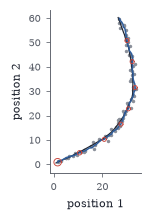

In [3]:
rng = np.random.default_rng(1); dt = 1.0; Fk = np.eye(4); Fk[0, 2] = Fk[1, 3] = dt; Hk = np.zeros((2, 4)); Hk[0, 0] = Hk[1, 1] = 1
Qk = 0.002 * np.eye(4); Rk = 0.6 * np.eye(2); xt = np.array([0, 0, 1, 0.5]); xh = np.zeros(4); Pk = 10 * np.eye(4); true_, meas_, est_, covs = [], [], [], []
for k in range(80):
    xt = Fk @ xt + rng.multivariate_normal(np.zeros(4), Qk); y = Hk @ xt + rng.multivariate_normal(np.zeros(2), Rk)
    xh = Fk @ xh; Pk = Fk @ Pk @ Fk.T + Qk; Kg = Pk @ Hk.T @ np.linalg.inv(Hk @ Pk @ Hk.T + Rk); xh = xh + Kg @ (y - Hk @ xh); Pk = (np.eye(4) - Kg @ Hk) @ Pk
    true_.append(xt[:2]); meas_.append(y); est_.append(xh[:2].copy()); covs.append(Pk[:2, :2].copy())
true_, meas_, est_ = map(np.array, (true_, meas_, est_))
fig, ax = plt.subplots(figsize=(W * 0.8, 1.9))
ax.plot(meas_[:, 0], meas_[:, 1], ".", color=GRAY, ms=2.5); ax.plot(true_[:, 0], true_[:, 1], color=INK, lw=0.8); ax.plot(est_[:, 0], est_[:, 1], color=BLUE, lw=1)
th = np.linspace(0, 2 * np.pi, 60)
for k in range(0, 80, 10):
    lam, U = np.linalg.eigh(covs[k]); E = U @ (2 * np.sqrt(lam)[:, None] * np.vstack([np.cos(th), np.sin(th)])); ax.plot(est_[k, 0] + E[0], est_[k, 1] + E[1], color=RED, lw=0.6)
ax.set_aspect("equal"); ax.set_xlabel("position 1"); ax.set_ylabel("position 2")

Sample covariance in high dimension. True covariance $\Sigma=I_{200}$, $N=400$ samples ($\gamma=p/N=0.5$). Left: the histogram of sample eigenvalues spreads over $[(1-\sqrt\gamma)^2,(1+\sqrt\gamma)^2]\approx[0.09,2.9]$ (Marchenko–Pastur density in red), although every true eigenvalue is $1$. Right: Frobenius error $\lVert\hat\Sigma_\alpha-\Sigma\rVert_F$ of the shrinkage estimator against $\alpha$, for a true covariance with spread-out eigenvalues; the Ledoit–Wolf choice (red dot) is close to the optimum.

Text(0, 0.5, 'Frobenius error')

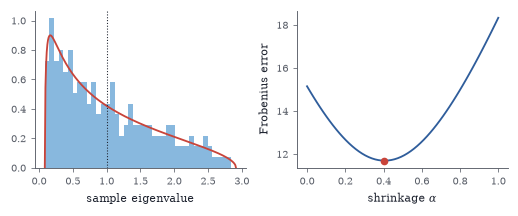

In [4]:
rng = np.random.default_rng(2); p, N = 200, 400; Xs = rng.normal(size=(N, p)); Sh = Xs.T @ Xs / N; ev = np.linalg.eigvalsh(Sh); gam = p / N
lo, hi = (1 - np.sqrt(gam)) ** 2, (1 + np.sqrt(gam)) ** 2; xx = np.linspace(lo, hi, 300); mp = np.sqrt((hi - xx) * (xx - lo)) / (2 * np.pi * gam * xx)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85))
axs[0].hist(ev, bins=40, density=True, color=SKY, alpha=0.8); axs[0].plot(xx, mp, color=RED); axs[0].axvline(1, color=INK, ls=":", lw=0.7); axs[0].set_xlabel("sample eigenvalue")
lt = np.geomspace(0.2, 5, p); Qr, _ = np.linalg.qr(rng.normal(size=(p, p))); Sig = (Qr * lt) @ Qr.T; Xc = rng.normal(size=(N, p)) @ np.linalg.cholesky(Sig).T; Xc -= Xc.mean(0); Sc = Xc.T @ Xc / N
tau = np.trace(Sc) / p; alphas = np.linspace(0, 1, 60); errs = [np.linalg.norm((1 - a) * Sc + a * tau * np.eye(p) - Sig) for a in alphas]
b2 = np.mean([np.linalg.norm(np.outer(x, x) - Sc) ** 2 for x in Xc]) / N; d2 = np.linalg.norm(Sc - tau * np.eye(p)) ** 2; a_lw = min(1, b2 / d2)
axs[1].plot(alphas, errs, color=BLUE); axs[1].plot(a_lw, np.linalg.norm((1 - a_lw) * Sc + a_lw * tau * np.eye(p) - Sig), "o", color=RED, ms=4); axs[1].set_xlabel(r"shrinkage $\alpha$"); axs[1].set_ylabel("Frobenius error")

In [5]:
Sg = np.array([[4., 2], [2, 2]]); Lc = np.linalg.cholesky(Sg)
for v in ([2., 0], [0., 2]):
    v = np.array(v); print(v, " Mahalanobis:", round(np.sqrt(v @ np.linalg.solve(Sg, v)), 6), "  whitened norm:", round(np.linalg.norm(np.linalg.solve(Lc, v)), 6))

[2. 0.]  Mahalanobis: 1.414214   whitened norm: 1.414214
[0. 2.]  Mahalanobis: 2.0   whitened norm: 2.0


In [6]:
Sg = np.array([[2., 1, 0], [1, 2, 1], [0, 1, 2]]); print("precision * 4:\n", np.round(4 * np.linalg.inv(Sg), 6))
c = Sg[0, 1:] @ np.linalg.inv(Sg[1:, 1:]); print("coefficients:", c, " mean:", c @ [1, 1], " variance:", Sg[0, 0] - c @ Sg[1:, 0])

precision * 4:
 [[ 3. -2.  1.]
 [-2.  4. -2.]
 [ 1. -2.  3.]]
coefficients: [ 0.66666667 -0.33333333]  mean: 0.3333333333333333  variance: 1.3333333333333335


In [7]:
y = np.array([10., 13, 12]); one = np.ones(3)
for rho in (0, 0.9, -0.9):
    Sg = np.diag([1., 4, 4]); Sg[1, 2] = Sg[2, 1] = 4 * rho; w = np.linalg.solve(Sg, one); v = 1 / (one @ w)
    print(f"rho={rho:+.1f}  weights={np.round(w * v, 4)}  estimate={w @ y * v:.4f}  variance={v:.4f}")

rho=+0.0  weights=[0.6667 0.1667 0.1667]  estimate=10.8333  variance=0.6667
rho=+0.9  weights=[0.7917 0.1042 0.1042]  estimate=10.5208  variance=0.7917
rho=-0.9  weights=[0.1667 0.4167 0.4167]  estimate=12.0833  variance=0.1667


In [8]:
q, r = 0.1, 1.0; P = 100.0
for k in range(30): Pm = P + q; K = Pm / (Pm + r); P = (1 - K) * Pm
Pinf = (-q + np.sqrt(q * q + 4 * q * r)) / 2
print("iterated P:", round(P, 6), " formula:", round(Pinf, 6), " gain:", round(K, 6), " sqrt(q/r):", round(np.sqrt(q / r), 4))

iterated P: 0.270156  formula: 0.270156  gain: 0.270156  sqrt(q/r): 0.3162


In [9]:
rng = np.random.default_rng(3); n, m = 4, 2; B = rng.normal(size=(n, n)); Pm = B @ B.T + np.eye(n); H = rng.normal(size=(m, n)); R = np.diag([0.5, 2.0])
P1 = Pm - Pm @ H.T @ np.linalg.solve(H @ Pm @ H.T + R, H @ Pm); P2 = np.linalg.inv(np.linalg.inv(Pm) + H.T @ np.linalg.solve(R, H))
print("max difference between the two forms:", np.abs(P1 - P2).max())

max difference between the two forms: 9.769962616701378e-15


In [10]:
rng = np.random.default_rng(4); p, N = 10, 30; acc = np.zeros((p, p))
for _ in range(4000):
    X = rng.normal(size=(N, p)); X -= X.mean(0); acc += np.linalg.inv(X.T @ X / N)
print("average diagonal of inverse:", round(np.mean(np.diag(acc / 4000)), 4), "  predicted N/(N-p-2):", round(N / (N - p - 2), 4))

average diagonal of inverse: 1.6741   predicted N/(N-p-2): 1.6667


In [11]:
rng = np.random.default_rng(5); p, N = 100, 60; lt = np.linspace(0.5, 2, p); Sig = np.diag(lt)
X = rng.normal(size=(N, p)) * np.sqrt(lt); X -= X.mean(0); S = X.T @ X / N; tau = np.trace(S) / p
b2 = np.mean([np.linalg.norm(np.outer(x, x) - S) ** 2 for x in X]) / N; d2 = np.linalg.norm(S - tau * np.eye(p)) ** 2; a = min(1, b2 / d2)
Slw = (1 - a) * S + a * tau * np.eye(p); ev = np.linalg.eigvalsh(S)
print(f"alpha={a:.3f}   Frobenius error: sample {np.linalg.norm(S - Sig):.3f}, Ledoit-Wolf {np.linalg.norm(Slw - Sig):.3f}")
print(f"smallest sample eigenvalue {ev[0]:.1e};  condition number of Ledoit-Wolf {np.linalg.cond(Slw):.2f} (true {lt.max() / lt.min():.1f})")
print(f"relative error of the inverse (Ledoit-Wolf): {np.linalg.norm(np.linalg.inv(Slw) - np.linalg.inv(Sig)) / np.linalg.norm(np.linalg.inv(Sig)):.3f}")

alpha=0.923   Frobenius error: sample 16.011, Ledoit-Wolf 4.237
smallest sample eigenvalue -1.6e-15;  condition number of Ledoit-Wolf 1.45 (true 4.0)


relative error of the inverse (Ledoit-Wolf): 0.391


In [12]:
p = 7; Lam = 2 * np.eye(p) - 0.9 * (np.eye(p, k=1) + np.eye(p, k=-1)); Sg = np.linalg.inv(Lam); d = np.sqrt(np.diag(Sg))
print("correlations from x1:", np.round(Sg[0] / (d[0] * d), 3))

correlations from x1: [1.    0.53  0.315 0.192 0.117 0.069 0.037]


In [13]:
z = np.array([1.0, 0.2, -0.5, 2.0]); pz = np.exp(z) / np.exp(z).sum(); F = np.diag(pz) - np.outer(pz, pz)
print("eigenvalues of F:", np.round(np.linalg.eigvalsh(F), 5), "   F @ 1 =", np.round(F @ np.ones(4), 12))

eigenvalues of F: [0.      0.06107 0.13502 0.35571]    F @ 1 = [ 0. -0.  0.  0.]


In [14]:
n = np.arange(1, 1001)
for name, x in [("last digit", n % 10), ("last digit of square", n**2 % 10), ("first digit", np.array([int(str(k)[0]) for k in n]))]:
    print(f"{name:22s} mean {x.mean():.4f}  variance {x.var():.4f}")
s = np.array([157, 312, 696, 602]) ** 2 % 10; print("samples:", s, " sample mean", s.mean(), " sample variance", round(s.var(ddof=1), 4))

last digit             mean 4.5000  variance 8.2500
last digit of square   mean 4.5000  variance 9.0500
first digit            mean 4.9960  variance 6.6760
samples: [9 4 6 4]  sample mean 5.75  sample variance 5.5833


In [15]:
rng = np.random.default_rng(7); N = 10**6; Xs = [(rng.integers(0, 2, N).mean() - 0.5) * 2 * np.sqrt(N) for _ in range(200)]
print("one run:", round(Xs[0], 4), "   over 200 runs: mean %.3f, std %.3f" % (np.mean(Xs), np.std(Xs)))

one run: 1.212    over 200 runs: mean -0.037, std 0.940


In [16]:
print("two dice x 36:", np.convolve(np.ones(6), np.ones(6)).astype(int))

two dice x 36: [1 2 3 4 5 6 5 4 3 2 1]


In [17]:
P = np.array([[0, 0.99, 0], [0.99, 0, 0], [0.01, 0.01, 1]]); print("eigenvalues:", np.round(np.linalg.eigvals(P), 4)); print("P^500:\n", np.round(np.linalg.matrix_power(P, 500), 4))

eigenvalues: [ 1.    0.99 -0.99]
P^500:
 [[0.0066 0.     0.    ]
 [0.     0.0066 0.    ]
 [0.9934 0.9934 1.    ]]
